In [12]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from plotly.subplots import make_subplots
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import (GridSearchCV ,train_test_split , StratifiedKFold, cross_val_score)
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler , LabelEncoder , OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (AdaBoostClassifier ,GradientBoostingClassifier ,RandomForestClassifier, VotingClassifier,ExtraTreesClassifier)
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (recall_score, confusion_matrix, precision_score, f1_score, accuracy_score, classification_report,roc_curve,precision_recall_curve)

In [13]:

from pathlib import Path
import pandas as pd

# Set the project directory
project_dir = Path(r"C:\Users\Brooz\my_churn_app")

# Set the dataset path
csv_file_name = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
file_path = project_dir / csv_file_name

# Check whether the dataset exists
if not file_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {file_path}")

# Load the dataset
df = pd.read_csv(file_path)

# Validate the loaded data
if df.empty:
    raise ValueError("The dataset is empty.")

print("Dataset loaded successfully!")
print("Dataset path:", file_path)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Dataset loaded successfully!
Dataset path: C:\Users\Brooz\my_churn_app\WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset shape: (7043, 21)
Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [14]:

# Standardize column names and remove unnecessary whitespace
df.columns = df.columns.str.strip()

# Remove duplicate customer records
duplicate_count = df.duplicated(subset="customerID").sum()
print(f"Duplicate customer IDs: {duplicate_count}")

if duplicate_count > 0:
    df = df.drop_duplicates(subset="customerID", keep="first").copy()

# Clean text columns
text_cols = df.select_dtypes(include=["object"]).columns

for col in text_cols:
    df[col] = df[col].str.strip()

# Convert numeric columns
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].replace("", pd.NA),
    errors="coerce"
)

# Inspect missing TotalCharges before deciding how to handle them
missing_total = df["TotalCharges"].isna()

print("Missing TotalCharges:", int(missing_total.sum()))

if missing_total.any():
    print(
        df.loc[
            missing_total,
            ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
        ].head(20)
    )

    # In this dataset, a blank TotalCharges is expected for customers
    # whose tenure is zero.
    invalid_rows = missing_total & (df["tenure"] != 0)

    if invalid_rows.any():
        raise ValueError(
            "Missing TotalCharges found for customers with non-zero tenure."
        )

    df.loc[missing_total, "TotalCharges"] = 0

# Encode the target
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

if df["Churn"].isna().any():
    raise ValueError("Unexpected values found in Churn.")

# Check the cleaned dataset
print("\nDataset shape:", df.shape)
print("\nMissing values:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nTarget distribution:")
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

display(df.head())


Duplicate customer IDs: 0
Missing TotalCharges: 11
      customerID  tenure  MonthlyCharges  TotalCharges
488   4472-LVYGI       0           52.55           NaN
753   3115-CZMZD       0           20.25           NaN
936   5709-LVOEQ       0           80.85           NaN
1082  4367-NUYAO       0           25.75           NaN
1340  1371-DWPAZ       0           56.05           NaN
3331  7644-OMVMY       0           19.85           NaN
3826  3213-VVOLG       0           25.35           NaN
4380  2520-SGTTA       0           20.00           NaN
5218  2923-ARZLG       0           19.70           NaN
6670  4075-WKNIU       0           73.35           NaN
6754  2775-SEFEE       0           61.90           NaN

Dataset shape: (7043, 21)

Missing values:
Series([], dtype: int64)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [15]:

# Identify categorical columns from the current dataset
categorical_cols = df.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

existing_categorical_cols = [
    col for col in categorical_cols
    if col in df.columns
]

print("Available categorical columns:", existing_categorical_cols)
print("Number of categorical columns:", len(existing_categorical_cols))


Available categorical columns: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Number of categorical columns: 16


In [16]:
# len null
print(df.isnull().sum())


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [17]:

# Fit encoders on df (before drop, but without customerID
encoders = {}
for col in existing_categorical_cols:
    le = LabelEncoder()
    le.fit(df[col].astype(str).unique())
    encoders[col] = le
    print(f"Classes for {col}: {le.classes_}")

Classes for customerID: ['0002-ORFBO' '0003-MKNFE' '0004-TLHLJ' ... '9992-UJOEL' '9993-LHIEB'
 '9995-HOTOH']
Classes for gender: ['Female' 'Male']
Classes for Partner: ['No' 'Yes']
Classes for Dependents: ['No' 'Yes']
Classes for PhoneService: ['No' 'Yes']
Classes for MultipleLines: ['No' 'No phone service' 'Yes']
Classes for InternetService: ['DSL' 'Fiber optic' 'No']
Classes for OnlineSecurity: ['No' 'No internet service' 'Yes']
Classes for OnlineBackup: ['No' 'No internet service' 'Yes']
Classes for DeviceProtection: ['No' 'No internet service' 'Yes']
Classes for TechSupport: ['No' 'No internet service' 'Yes']
Classes for StreamingTV: ['No' 'No internet service' 'Yes']
Classes for StreamingMovies: ['No' 'No internet service' 'Yes']
Classes for Contract: ['Month-to-month' 'One year' 'Two year']
Classes for PaperlessBilling: ['No' 'Yes']
Classes for PaymentMethod: ['Bank transfer (automatic)' 'Credit card (automatic)' 'Electronic check'
 'Mailed check']


In [18]:

import os
import joblib
from pathlib import Path

# Save the label encoders
project_dir = Path(r"C:\Users\Brooz\my_churn_app")
models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

encoders_path = models_dir / "label_encoders.pkl"

joblib.dump(encoders, encoders_path)

print(f"Saved {len(encoders)} label encoders to: {encoders_path}")

# Check class imbalance
print("\nChurn distribution:")
print(df["Churn"].value_counts(normalize=True))


Saved 16 label encoders to: C:\Users\Brooz\my_churn_app\models\label_encoders.pkl

Churn distribution:
Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64


In [19]:
# Predict (drop Churn/ID، vectorized encode)
def predict(input_df, model, encoders):
    try:
        input_data = input_df.copy()
        
        # Numeric
        if 'TotalCharges' in input_data.columns:
            input_data['TotalCharges'] = pd.to_numeric(input_data['TotalCharges'], errors='coerce').fillna(0)
        if 'MonthlyCharges' in input_data.columns:
            input_data['MonthlyCharges'] = pd.to_numeric(input_data['MonthlyCharges'], errors='coerce').fillna(0)
        
        # Drop non-features
        if 'customerID' in input_data.columns:
            input_data = input_data.drop('customerID', axis=1)
        if 'Churn' in input_data.columns:
            input_data = input_data.drop('Churn', axis=1)
        
        # Encode
        encoded_df = input_data.copy()
        for col in encoders:
            if col in encoded_df.columns:
                classes = encoders[col].classes_
                mask = encoded_df[col].astype(str).isin(classes)
                encoded_df.loc[mask, col] = encoders[col].transform(encoded_df.loc[mask, col].astype(str))
                encoded_df.loc[~mask, col] = 0
        
        pred = model.predict(encoded_df)
        proba = model.predict_proba(encoded_df)[:, 1]
        return pred, proba
    except Exception as e:
        st.error(f"❌ Prediction error: {e}")
        print(f"Debug: {e}, Columns: {input_df.columns.tolist()}")
        return None, None
    


In [20]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
print(df[numerical_cols].describe())

            tenure  MonthlyCharges  TotalCharges
count  7043.000000     7043.000000   7043.000000
mean     32.371149       64.761692   2279.734304
std      24.559481       30.090047   2266.794470
min       0.000000       18.250000      0.000000
25%       9.000000       35.500000    398.550000
50%      29.000000       70.350000   1394.550000
75%      55.000000       89.850000   3786.600000
max      72.000000      118.750000   8684.800000


In [21]:
# Unique print for gender and a few others
for col in ['gender', 'MultipleLines', 'InternetService']:
    print(f"{col}: {df[col].unique()}")

gender: ['Female' 'Male']
MultipleLines: ['No phone service' 'No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']


In [22]:
churn_analysis = df.groupby("SeniorCitizen")["Churn"].value_counts(normalize=True).unstack()
print(churn_analysis)

Churn                 0         1
SeniorCitizen                    
0              0.763938  0.236062
1              0.583187  0.416813


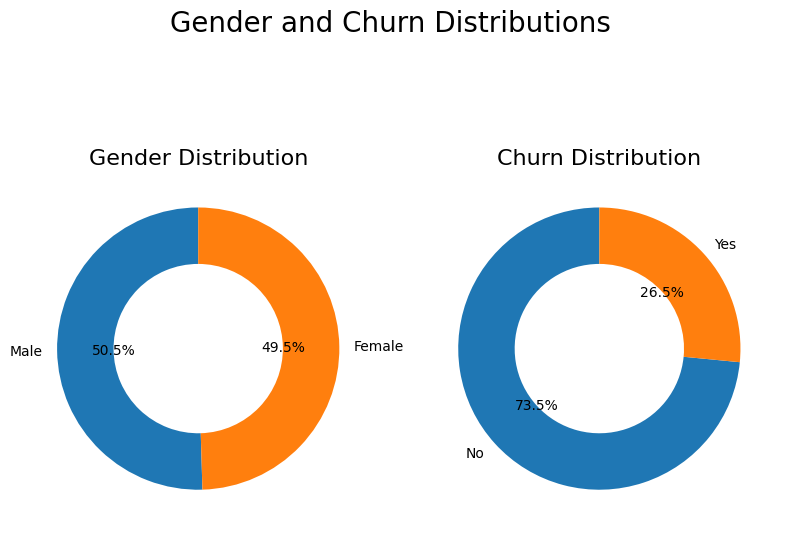

In [23]:

g_labels = ['Male', 'Female']
c_labels = ['No', 'Yes']
gender_counts = df['gender'].value_counts()
churn_counts = df['Churn'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(8,6))
wedges_gender, texts_gender, autotexts_gender = axes[0].pie(gender_counts, labels=g_labels, autopct='%1.1f%%', startangle=90, wedgeprops={'width': 0.4})
axes[0].set_title('Gender Distribution', fontsize=16)
wedges_churn, texts_churn, autotexts_churn = axes[1].pie(churn_counts, labels=c_labels, autopct='%1.1f%%', startangle=90, wedgeprops={'width': 0.4})
axes[1].set_title('Churn Distribution', fontsize=16)
fig.suptitle("Gender and Churn Distributions", fontsize=20, y=1.02)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()


In [24]:
print(df["Churn"][df["Churn"]==0].groupby(by=df["gender"]).count())
print(df["Churn"][df["Churn"]==1].groupby(by=df["gender"]).count())

gender
Female    2549
Male      2625
Name: Churn, dtype: int64
gender
Female    939
Male      930
Name: Churn, dtype: int64


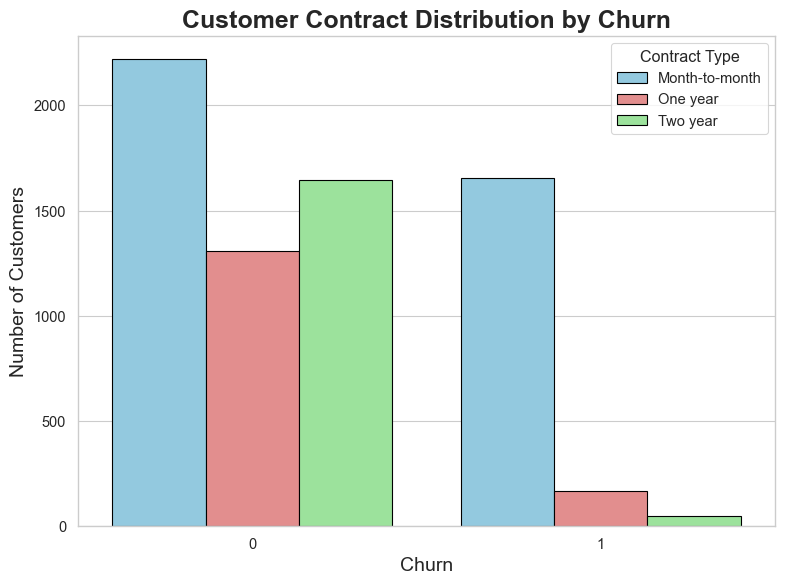

In [25]:

sns.set_style("whitegrid")
sns.set_context("paper", font_scale=1.2)
colors = {'Month-to-month': 'skyblue', 'One year': 'lightcoral', 'Two year': 'lightgreen'}
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='Churn', hue='Contract', palette=colors, edgecolor='black')
plt.title("Customer Contract Distribution by Churn", fontsize=18, weight='bold')
plt.xlabel("Churn", fontsize=14)
plt.ylabel("Number of Customers", fontsize=14)
plt.legend(title="Contract Type", loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

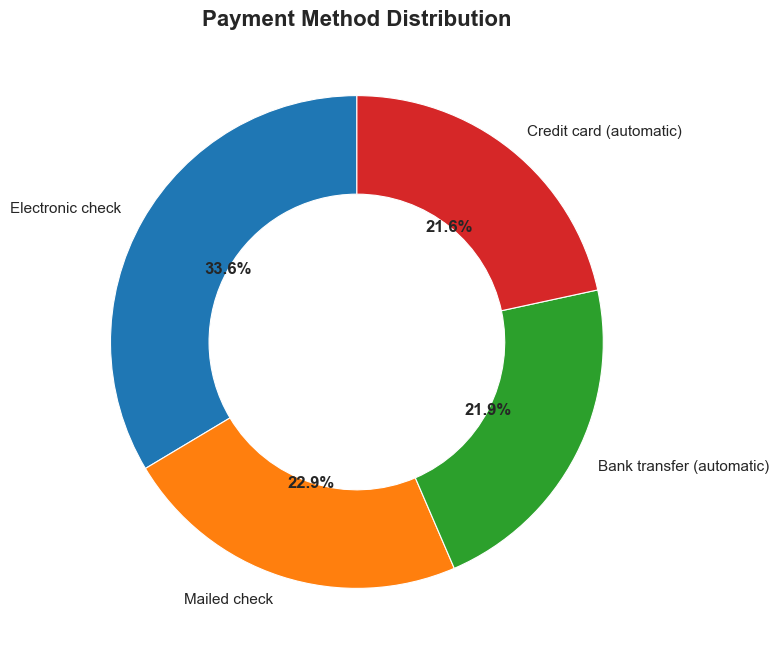

In [26]:

labels = df['PaymentMethod'].unique()
values = df['PaymentMethod'].value_counts()
fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(values, labels=labels, autopct='%1.1f%%', startangle=90, wedgeprops={'width': 0.4})
ax.set_title("Payment Method Distribution", fontsize=16, weight='bold')
ax.set_aspect('equal')
plt.setp(autotexts, size=12, weight="bold")
plt.setp(texts, size=11)
plt.show()

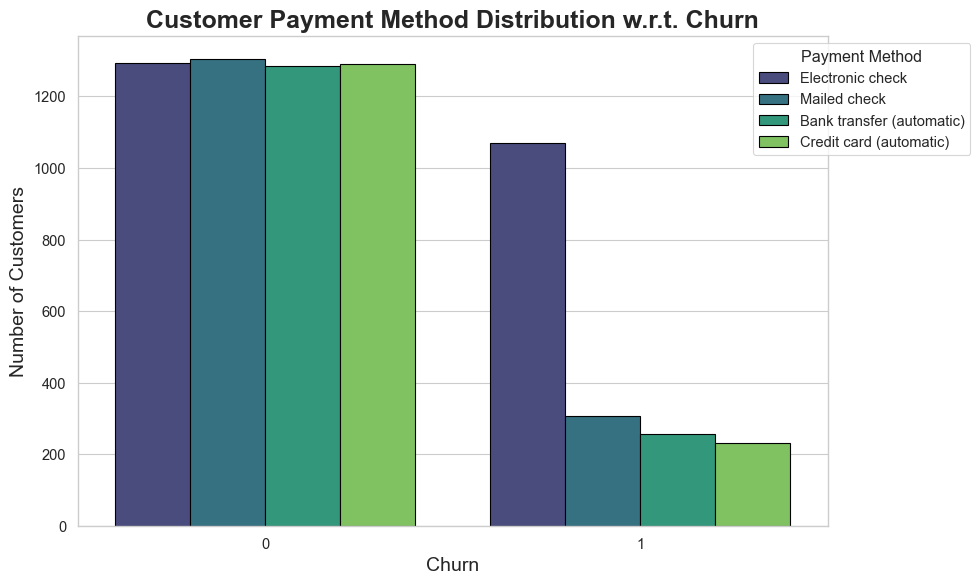

In [27]:
sns.set_style("whitegrid")
sns.set_context("paper", font_scale=1.2)
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Churn', hue='PaymentMethod', palette='viridis', edgecolor='black')
plt.title("Customer Payment Method Distribution w.r.t. Churn", fontsize=18, weight='bold')
plt.xlabel("Churn", fontsize=14)
plt.ylabel("Number of Customers", fontsize=14)
plt.legend(title="Payment Method", loc='upper right', bbox_to_anchor=(1.2, 1), frameon=True)
plt.tight_layout()
plt.show()

In [28]:
print(df["InternetService"].unique())
print(df[df["gender"]=="Male"][["InternetService", "Churn"]].value_counts())
print(df[df["gender"]=="Female"][["InternetService", "Churn"]].value_counts())

['DSL' 'Fiber optic' 'No']
InternetService  Churn
DSL              0        993
Fiber optic      0        910
No               0        722
Fiber optic      1        633
DSL              1        240
No               1         57
Name: count, dtype: int64
InternetService  Churn
DSL              0        969
Fiber optic      0        889
No               0        691
Fiber optic      1        664
DSL              1        219
No               1         56
Name: count, dtype: int64


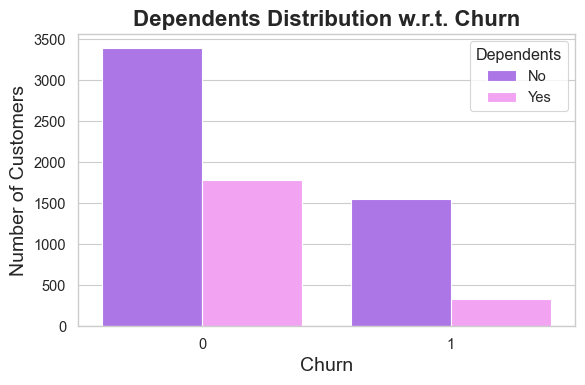

In [29]:
color_map_seaborn = {"Yes": "#FF97FF", "No": "#AB63FA"}
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn', hue='Dependents', palette=color_map_seaborn)
plt.title("Dependents Distribution w.r.t. Churn", fontsize=16, weight='bold')
plt.xlabel("Churn", fontsize=14)
plt.ylabel("Number of Customers", fontsize=14)
plt.legend(title="Dependents", loc='upper right')
plt.tight_layout()
plt.show()

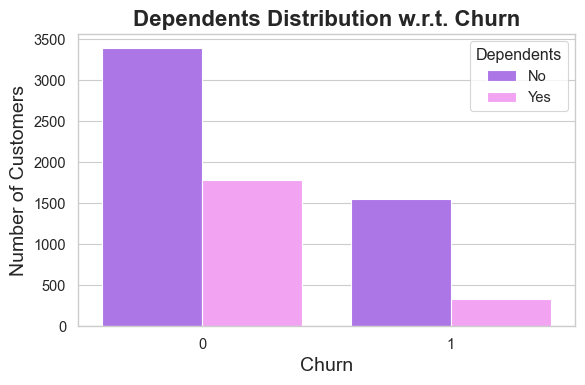

In [30]:
color_map_seaborn = {"Yes": "#FF97FF", "No": "#AB63FA"}
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn', hue='Dependents', palette=color_map_seaborn)
plt.title("Dependents Distribution w.r.t. Churn", fontsize=16, weight='bold')
plt.xlabel("Churn", fontsize=14)
plt.ylabel("Number of Customers", fontsize=14)
plt.legend(title="Dependents", loc='upper right')
plt.tight_layout()
plt.show()

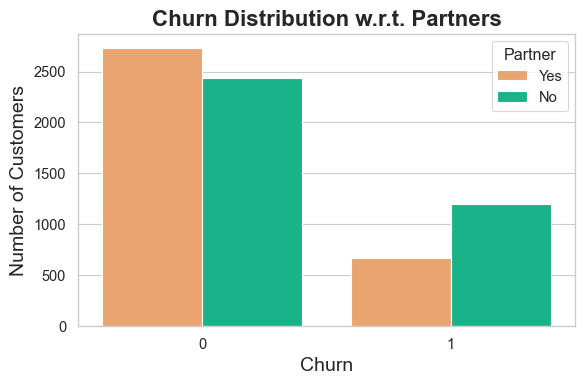

In [31]:
color_map_seaborn = {"Yes": '#FFA15A', "No": '#00CC96'}
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn', hue='Partner', palette=color_map_seaborn)
plt.title("Churn Distribution w.r.t. Partners", fontsize=16, weight='bold')
plt.xlabel("Churn", fontsize=14)
plt.ylabel("Number of Customers", fontsize=14)
plt.legend(title="Partner", loc='upper right')
plt.tight_layout()
plt.show()

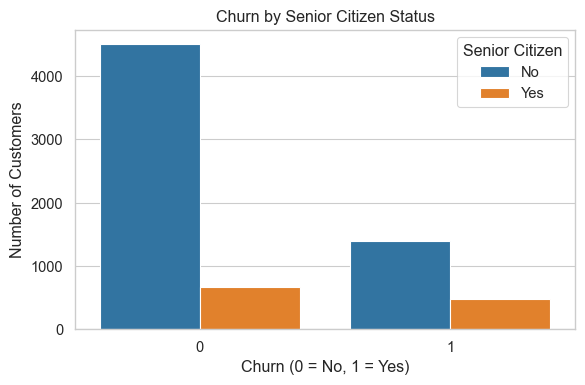

In [32]:

senior_labels = df["SeniorCitizen"].map({
    0: "No",
    1: "Yes"
})

plot_df = df.assign(SeniorCitizenLabel=senior_labels)

plt.figure(figsize=(6, 4))

sns.countplot(
    data=plot_df,
    x="Churn",
    hue="SeniorCitizenLabel",
    order=[0, 1],
    hue_order=["No", "Yes"]
)

plt.title("Churn by Senior Citizen Status")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.legend(title="Senior Citizen")
plt.tight_layout()
plt.show()


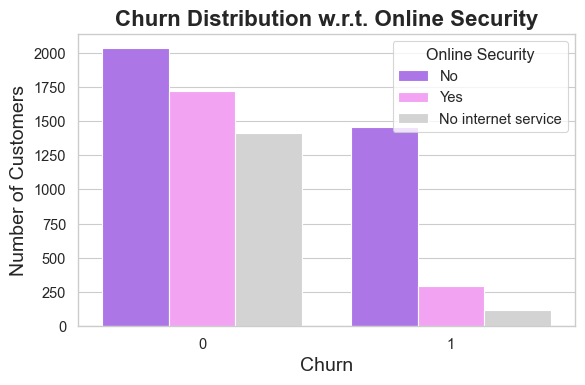

In [33]:
color_map_seaborn = {"Yes": "#FF97FF", "No": "#AB63FA", "No internet service": "#D3D3D3"}
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn', hue='OnlineSecurity', palette=color_map_seaborn)
plt.title("Churn Distribution w.r.t. Online Security", fontsize=16, weight='bold')
plt.xlabel("Churn", fontsize=14)
plt.ylabel("Number of Customers", fontsize=14)
plt.legend(title="Online Security", loc='upper right')
plt.tight_layout()
plt.show()

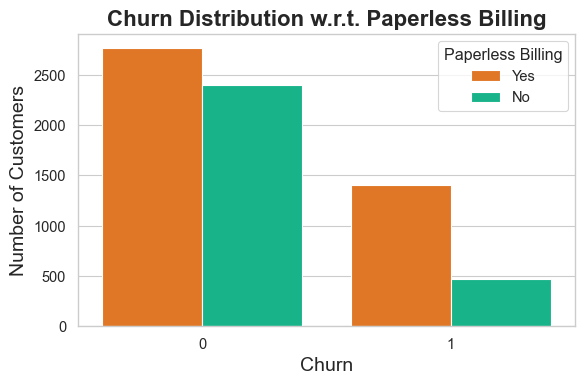

In [34]:
color_map_seaborn = {"Yes": "#FF7308", "No": '#00CC96'}
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn', hue='PaperlessBilling', palette=color_map_seaborn)
plt.title("Churn Distribution w.r.t. Paperless Billing", fontsize=16, weight='bold')
plt.xlabel("Churn", fontsize=14)
plt.ylabel("Number of Customers", fontsize=14)
plt.legend(title="Paperless Billing", loc='upper right')
plt.tight_layout()
plt.show()

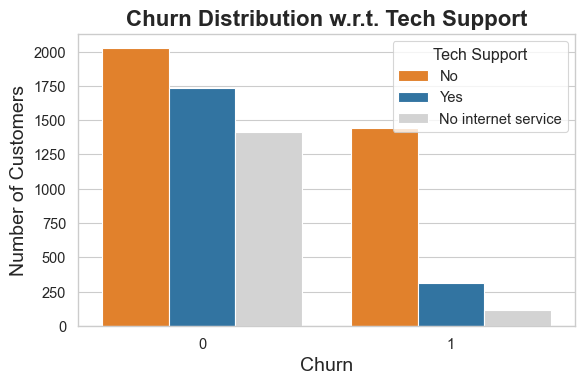

In [35]:

color_map_seaborn = {"Yes": '#1f77b4', "No": '#ff7f0e', "No internet service": '#d3d3d3'}
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn', hue='TechSupport', palette=color_map_seaborn)
plt.title("Churn Distribution w.r.t. Tech Support", fontsize=16, weight='bold')
plt.xlabel("Churn", fontsize=14)
plt.ylabel("Number of Customers", fontsize=14)
plt.legend(title="Tech Support", loc='upper right')
plt.tight_layout()
plt.show()

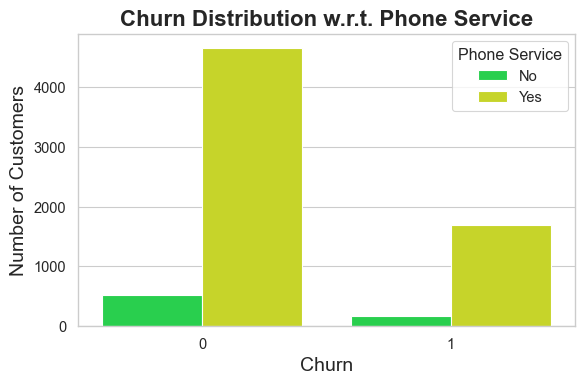

In [36]:
color_map_seaborn = {"Yes": "#DEF10D", "No": "#0EEA3E"}
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn', hue='PhoneService', palette=color_map_seaborn)
plt.title("Churn Distribution w.r.t. Phone Service", fontsize=16, weight='bold')
plt.xlabel("Churn", fontsize=14)
plt.ylabel("Number of Customers", fontsize=14)
plt.legend(title="Phone Service", loc='upper right')
plt.tight_layout()
plt.show()

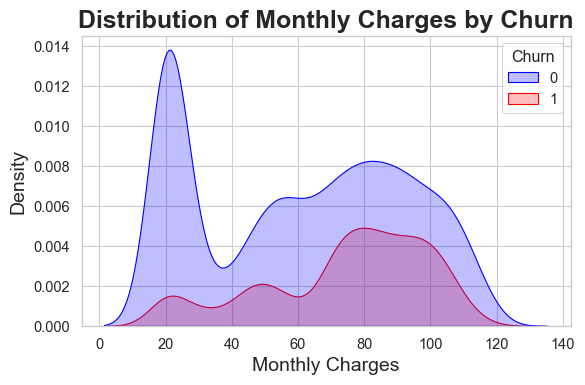

In [37]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', fill=True, palette=['blue', 'red'])
plt.title("Distribution of Monthly Charges by Churn", fontsize=18, weight='bold')
plt.xlabel("Monthly Charges", fontsize=14)
plt.ylabel("Density", fontsize=14)
plt.tight_layout()
plt.show()

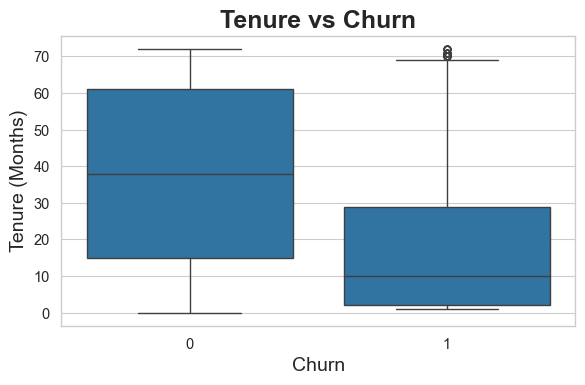

In [38]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x='Churn', y='tenure')
plt.title("Tenure vs Churn", fontsize=18, weight='bold')
plt.xlabel("Churn", fontsize=14)
plt.ylabel("Tenure (Months)", fontsize=14)
plt.tight_layout()
plt.show()

In [39]:

print(df["Churn"].value_counts())

target = "Churn"
X = df.drop(columns=[target])
y = df[target]

print(y.unique())

Churn
0    5174
1    1869
Name: count, dtype: int64
[0 1]


In [40]:
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()


In [41]:
# Splitting data with stratify to maintain class balance


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
) 




In [42]:
ID_COLS = ['CustomerID', 'InvoiceNo']
X = X.drop(columns=ID_COLS, errors='ignore')

In [43]:

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_cols)
    ],
    remainder='drop'
)

In [44]:
# Models with balanced settings for imbalance

baseline_pipelines = {
    'Dummy': ImbPipeline([
        ("prep", preprocessor),
        ("model", DummyClassifier(strategy='most_frequent'))
    ]),
    'Logistic': ImbPipeline([
        ("prep", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    'Shallow DT': ImbPipeline([
        ("prep", preprocessor),
        ("model", DecisionTreeClassifier(max_depth=3))
    ])
}

for name, pipe in baseline_pipelines.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    print(f"\n{name} — Baseline")
    print(classification_report(y_test, y_pred))


Dummy — Baseline
              precision    recall  f1-score   support

           0       0.73      1.00      0.85      1294
           1       0.00      0.00      0.00       467

    accuracy                           0.73      1761
   macro avg       0.37      0.50      0.42      1761
weighted avg       0.54      0.73      0.62      1761


Logistic — Baseline
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1294
           1       0.66      0.56      0.61       467

    accuracy                           0.81      1761
   macro avg       0.75      0.73      0.74      1761
weighted avg       0.80      0.81      0.80      1761


Shallow DT — Baseline
              precision    recall  f1-score   support

           0       0.79      0.95      0.86      1294
           1       0.68      0.30      0.42       467

    accuracy                           0.78      1761
   macro avg       0.73      0.63      0.64      1761
weighted avg

In [45]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), cat_cols)
    ]
)


In [46]:
# ۱. پیش‌پردازش داده‌ها مستقیماً
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.over_sampling import SMOTE

# تعریف preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), cat_cols)
    ]
)

# ۲. پردازش داده‌ها
print("پردازش داده‌ها...")
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# ۳. اعمال SMOTE
print("اعمال SMOTE...")
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_processed, y_train)

print(f"قبل از SMOTE: {X_train_processed.shape}, کلاس‌ها: {np.bincount(y_train)}")
print(f"بعد از SMOTE: {X_train_resampled.shape}, کلاس‌ها: {np.bincount(y_train_resampled)}")

# ۴. آموزش CatBoost مستقیماً
print("\nآموزش CatBoost...")
from catboost import CatBoostClassifier

catboost_model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.03,
    depth=6,
    l2_leaf_reg=3,
    border_count=32,
    loss_function='Logloss',
    verbose=0,
    random_state=42,
    task_type='CPU'
)

catboost_model.fit(X_train_resampled, y_train_resampled)
print("✅ CatBoost آموزش داده شد")

# ۵. پیش‌بینی و ارزیابی
y_pred = catboost_model.predict(X_test_processed)
y_pred_proba = catboost_model.predict_proba(X_test_processed)[:, 1]

# ارزیابی
from sklearn.metrics import (
    classification_report, confusion_matrix, 
    accuracy_score, f1_score, roc_auc_score,
    precision_score, recall_score
)

print("\n" + "="*50)
print("ارزیابی CatBoost روی داده Test")
print("="*50)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_pred_proba):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

پردازش داده‌ها...
اعمال SMOTE...
قبل از SMOTE: (5282, 5311), کلاس‌ها: [3880 1402]
بعد از SMOTE: (7760, 5311), کلاس‌ها: [3880 3880]

آموزش CatBoost...
✅ CatBoost آموزش داده شد

ارزیابی CatBoost روی داده Test
Accuracy:  0.7927
F1 Score:  0.6170
Precision: 0.6049
Recall:    0.6296
ROC-AUC:   0.8455

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.85      0.86      1294
           1       0.60      0.63      0.62       467

    accuracy                           0.79      1761
   macro avg       0.73      0.74      0.74      1761
weighted avg       0.80      0.79      0.79      1761

Confusion Matrix:
[[1102  192]
 [ 173  294]]


In [47]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

model_zoo = {
    "Logistic": LogisticRegression(max_iter=1000, random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=42
    ),
    "LightGBM": LGBMClassifier(random_state=42)
}


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for name, model in model_zoo.items():
    pipe = ImbPipeline(steps=[
        ("prep", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", model)
    ])
    
    scores = cross_val_score(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )
    
    results.append({
        "Model": name,
        "Mean_F1": scores.mean(),
        "Std_F1": scores.std()
    })

model_comparison_df = pd.DataFrame(results).sort_values(
    by="Mean_F1", ascending=False
)

model_comparison_df


,Model,Mean_F1,Std_F1
0,Logistic,0.630134,0.017774
2,CatBoost,0.626685,0.023092
3,XGBoost,0.604038,0.023662
4,LightGBM,0.593187,0.018948
1,RandomForest,0.587784,0.014588


In [48]:
pipelines = {
    "Logistic": ImbPipeline(steps=[
        ("prep", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    
    "RandomForest": ImbPipeline(steps=[
        ("prep", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", RandomForestClassifier(n_estimators=300, random_state=42))
    ]),
    
    "CatBoost": ImbPipeline(steps=[
        ("prep", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", CatBoostClassifier(verbose=0, random_state=42))
    ])
}


In [49]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, pipe in pipelines.items():
    scores = cross_val_score(
    pipe,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

    print(f"{name} — Mean F1: {scores.mean():.3f}")

Logistic — Mean F1: 0.733
RandomForest — Mean F1: 0.726
CatBoost — Mean F1: 0.745


In [50]:

best_model_name = "CatBoost"
best_model = pipelines[best_model_name]

best_model.fit(X_train, y_train)

print(f"Final model: {best_model_name}")
print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")
print("Model training completed.")


Final model: CatBoost
Training rows: 5282
Test rows: 1761
Model training completed.


In [51]:

# Predict with the complete pipeline
y_probs = best_model.predict_proba(X_test)[:, 1]

thresholds_to_check = [0.25, 0.30, 0.35, 0.40, 0.50]

for threshold in thresholds_to_check:
    y_pred_threshold = (y_probs >= threshold).astype(int)

    print(f"\nThreshold: {threshold:.2f}")
    print(
        classification_report(
            y_test,
            y_pred_threshold,
            labels=[0, 1],
            target_names=["No Churn", "Churn"],
            zero_division=0,
            digits=3
        )
    )



Threshold: 0.25
              precision    recall  f1-score   support

    No Churn      0.929     0.655     0.768      1294
       Churn      0.474     0.861     0.611       467

    accuracy                          0.710      1761
   macro avg      0.701     0.758     0.690      1761
weighted avg      0.808     0.710     0.727      1761


Threshold: 0.30
              precision    recall  f1-score   support

    No Churn      0.918     0.707     0.799      1294
       Churn      0.504     0.824     0.626       467

    accuracy                          0.738      1761
   macro avg      0.711     0.766     0.712      1761
weighted avg      0.808     0.738     0.753      1761


Threshold: 0.35
              precision    recall  f1-score   support

    No Churn      0.909     0.747     0.820      1294
       Churn      0.531     0.792     0.636       467

    accuracy                          0.759      1761
   macro avg      0.720     0.770     0.728      1761
weighted avg      0.809

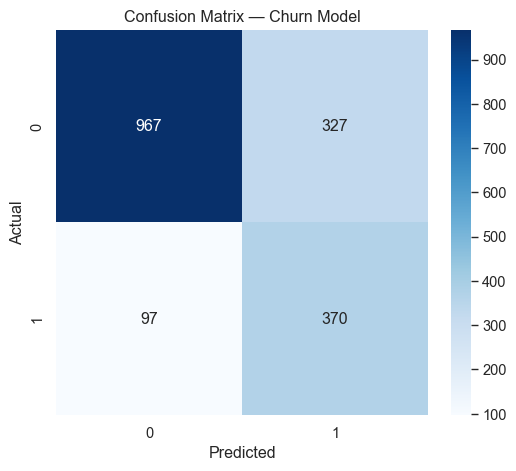

In [52]:
threshold = 0.35
y_pred = (y_probs >= threshold).astype(int)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — Churn Model")
plt.show()

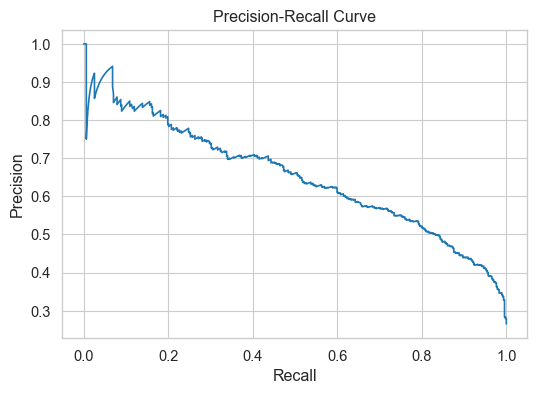

In [53]:
precision, recall, thresholds = precision_recall_curve(y_test, y_probs)

plt.figure(figsize=(6,4))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.show()

In [54]:
# هزینه‌ها (اینها را می‌توانی از مشتری بگیری)
COST_FN = 500   # هزینه از دست دادن یک مشتری (CLV)
COST_FP = 50    # هزینه اقدام اشتباه (تماس، تخفیف، کمپین)


In [55]:
optimal_threshold = COST_FP / (COST_FP + COST_FN)
print(f"Optimal Threshold (Cost-based): {optimal_threshold:.3f}")

Optimal Threshold (Cost-based): 0.091


In [56]:
y_pred_cost_based = (y_probs >= optimal_threshold).astype(int)

In [57]:
print("Cost-based Threshold Results")
print(classification_report(y_test, y_pred_cost_based, digits=3))

Cost-based Threshold Results
              precision    recall  f1-score   support

           0      0.975     0.430     0.597      1294
           1      0.381     0.970     0.547       467

    accuracy                          0.574      1761
   macro avg      0.678     0.700     0.572      1761
weighted avg      0.818     0.574     0.584      1761



In [58]:

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_cost_based).ravel()

total_cost = fp * COST_FP + fn * COST_FN

print(f"False Positives cost: {fp * COST_FP}")
print(f"False Negatives cost: {fn * COST_FN}")
print(f"Total Business Cost: {total_cost}")


False Positives cost: 36850
False Negatives cost: 7000
Total Business Cost: 43850


In [59]:
thresholds_to_test = [0.1, 0.2, 0.3, 0.4, 0.5]
results = []

for t in thresholds_to_test:
    y_pred_t = (y_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    cost = fp * COST_FP + fn * COST_FN
    
    results.append({
        'threshold': t,
        'FP': fp,
        'FN': fn,
        'Total_Cost': cost
    })

pd.DataFrame(results)


,threshold,FP,FN,Total_Cost
0,0.1,708,16,43400
1,0.2,513,52,51650
2,0.3,379,82,59950
3,0.4,286,117,72800
4,0.5,199,174,96950


In [60]:
COST_FN = 1000   # هزینه از دست دادن یک مشتری (CLV)
COST_FP = 50     # هزینه تماس / تخفیف بیهوده


In [61]:
results_cost = []

for t in np.arange(0.1, 0.6, 0.05):
    y_pred = (y_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    
    total_cost = fn * COST_FN + fp * COST_FP
    
    results_cost.append({
        'threshold': round(t,2),
        'FN': fn,
        'FP': fp,
        'Total_Cost': total_cost
    })

cost_df = pd.DataFrame(results_cost)
cost_df


,threshold,FN,FP,Total_Cost
0,0.10,16,708,51400
1,0.15,35,597,64850
2,0.20,52,513,77650
3,0.25,65,446,87300
4,0.30,82,379,100950
5,0.35,97,327,113350
6,0.40,117,286,131300
7,0.45,142,246,154300
8,0.50,174,199,183950
9,0.55,203,159,210950


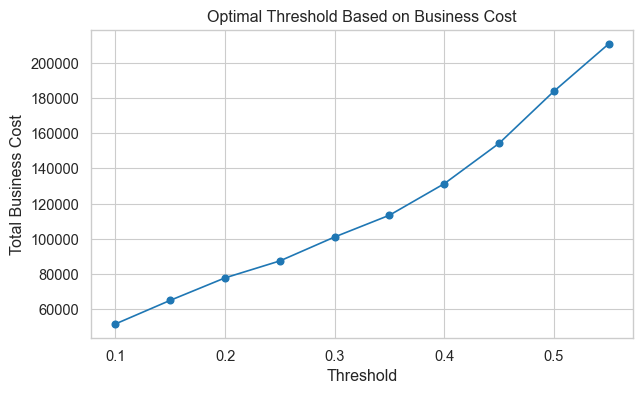

In [62]:
plt.figure(figsize=(7,4))
plt.plot(cost_df['threshold'], cost_df['Total_Cost'], marker='o')
plt.xlabel("Threshold")
plt.ylabel("Total Business Cost")
plt.title("Optimal Threshold Based on Business Cost")
plt.show()


In [63]:

import joblib
from pathlib import Path

# Define the project directory as a Path object
project_dir = Path.cwd()

# Set the model file path
model_path = project_dir / "voting_classifier_final_model.pkl"

# Save the trained model
joblib.dump(best_model, model_path)

print(f"Model saved to: {model_path.resolve()}")
print(f"Model type: {type(best_model).__name__}")



Model saved to: C:\Users\Brooz\AppData\Local\Temp\da04be3a-be6b-4187-a58f-4955d2062886_customer_churn-analysis-main (2).zip.886\customer_churn-analysis-main\voting_classifier_final_model.pkl
Model type: Pipeline


In [64]:

import joblib
import numpy as np

loaded_model = joblib.load(model_path)

test_predictions = loaded_model.predict(X_test)
test_probabilities = loaded_model.predict_proba(X_test)[:, 1]

print("Model loaded successfully.")
print("Predictions shape:", test_predictions.shape)
print("Probabilities shape:", test_probabilities.shape)

assert len(test_predictions) == len(y_test)
assert len(test_probabilities) == len(y_test)
assert np.isfinite(test_probabilities).all()
assert ((test_probabilities >= 0) & (test_probabilities <= 1)).all()

print("Model validation passed.")



Model loaded successfully.
Predictions shape: (1761,)
Probabilities shape: (1761,)
Model validation passed.
